# Phase 11: Extensions (S1–S4)

The Phase 11 review (`paper/draft/phase11_review.md`) found that our strongest result is the **generalization reversal**: the most accurate models on the familiar 50 VMs (LightGBM, Random Forest) were among the worst on 100 unseen VMs. The review also pointed out three weaknesses. The team approved four additions to fix them (4 Oct 2026):

| | What this notebook does | Why |
|---|---|---|
| **S1** | Retrain the 5 tabular models on **VM-agnostic features** (CPU% and memory% history plus time of day; no core count, no disk or network columns), then retest on the test set **and** the 100 unseen VMs | In Phase 9 we traced the failures to disk and network features. If removing them fixes generalization, we've shown both the cause and a fix |
| **S2** | **Robustness-aware TOPSIS**: add "MAE on unseen VMs" as a criterion, and rank all 11 model variants together | Lets the framework catch a problem that accuracy-only selection misses |
| **S3** | (a) TOPSIS with time and CO₂ **merged** into one cost criterion; (b) measure **inference** (prediction) energy; (c) project yearly CO₂ for a **realistic fleet** | (a) answers the "time and CO₂ are the same thing on Colab" objection; (b) deployment energy is mostly prediction, not training; (c) turns grams into a size that matters |
| **S4** | **Significance tests**: is XGBoost really different from LightGBM? | They tied in TOPSIS. A test tells us whether to call them equal |

**Same-session measurement:** all 11 model variants (6 originals + 5 VM-agnostic) are trained and timed with CodeCarbon **in this one Colab session**. Each new Colab session can land on different hardware, so mixing numbers from Phase 5 with numbers measured here wouldn't be a fair comparison. The original models use exactly the Phase 4 tuned settings, so their accuracy here matches the Phase 6 seed-42 run.

**Run time on free Colab:** about 20–25 minutes. **If Colab disconnects, run everything again.** Every measurement is saved as soon as it finishes, and finished ones are skipped.

## 0. Setup

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('codecarbon') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'codecarbon'], check=True)

In [2]:
# Mount Google Drive (Colab) or use the local Drive folder (PC), then load our shared code.
import os, sys, importlib

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/Green_ML_Project'
except ImportError:
    PROJECT_ROOT = r'H:\My Drive\Green_ML_Project'   # running on the PC instead of Colab

os.environ['GREEN_ML_ROOT'] = PROJECT_ROOT
sys.path.insert(0, os.path.join(PROJECT_ROOT, 'scripts'))

import config as C
import utils as U
importlib.reload(C); importlib.reload(U)   # picks up any edits to the scripts without restarting

print('Project folder:', C.PROJECT_ROOT)
print('Folder found:  ', os.path.isdir(C.PROJECT_ROOT))

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Green_ML_Project
Folder found:   True


In [3]:
import gc, json, math, os
import numpy as np
import pandas as pd
import joblib, torch
import matplotlib.pyplot as plt
from scipy import stats
import model_definitions as M, energy as E, plot_style as P
for mod in (M, E, P):
    importlib.reload(mod)
P.apply()

FORCE_RERUN = False
MIN_MEASURE_SEC = 30
log = U.get_logger('phase11_extensions')
log.info(f'CPU cores: {os.cpu_count()} | FORCE_RERUN = {FORCE_RERUN}')

# ---- Fleet scenario for S3(c). Change these to explore other scenarios; the notebook is cheap to rerun.
FLEET = {
    'n_vms': 10_000,                 # VMs whose CPU the provider forecasts
    'vms_per_model': C.N_TRAIN_VMS,  # one model per group of 50 VMs, like our experiment
    'retrains_per_day': 1,           # each model retrained daily on its recent data
    'prediction_interval_min': 5,    # one forecast per VM every 5 minutes (the trace's resolution)
    'days': 365,
}
log.info(f'Fleet scenario: {FLEET}')

RUN STARTED 2026-10-04 17:07:40 | phase11_extensions
python 3.13.15 | pandas 2.2.3 | numpy 2.1.3 | machine: Linux-6.6.122+-x86_64-with-glibc2.39
project root: /content/drive/MyDrive/Green_ML_Project
CPU cores: 2 | FORCE_RERUN = False
Fleet scenario: {'n_vms': 10000, 'vms_per_model': 50, 'retrains_per_day': 1, 'prediction_interval_min': 5, 'days': 365}


## 1. Load data and define the two feature sets

In [4]:
train = pd.read_parquet(C.DATA_PROCESSED / 'train.parquet')
test = pd.read_parquet(C.DATA_PROCESSED / 'test.parquet')
features_main = pd.read_parquet(C.DATA_PROCESSED / 'features_main.parquet')
gen = pd.read_parquet(C.DATA_PROCESSED / 'features_generalization.parquet')
phase4 = json.load(open(C.MODELS_DIR / 'phase4_results.json'))
phase5 = json.load(open(C.MODELS_DIR / 'phase5_results.json'))

FULL = list(U.FEATURE_COLUMNS)
DROPPED = ['cpu_cores'] + C.IO_COLUMNS
AGNOSTIC = [c for c in FULL if c not in DROPPED]
log.info(f'Full feature set ({len(FULL)}): {FULL}')
log.info(f'VM-agnostic set ({len(AGNOSTIC)}): {AGNOSTIC}  | dropped: {DROPPED}')

y_train, y_test = train[C.TARGET].to_numpy(), test[C.TARGET].to_numpy()

# Unseen-VM rows: the same rows Phase 9 scored (every model, incl. the LSTM, can predict them)
lstm_cfg = phase4['LSTM']['best_params']
_, _, common_idx = M.make_sequences(gen, lstm_cfg['seq_len'])
common = gen.loc[common_idx].reset_index(drop=True)
y_gen = common[C.TARGET].to_numpy()
log.info(f'Test rows: {len(test):,} | unseen-VM rows: {len(common):,}')

tuned_params = {n: (phase4[n]['best_params'] if n in phase4 else {}) for n in M.TABULAR_MODELS}

RESULTS_FILE = C.MODELS_DIR / 'phase11_results.json'
R = {} if FORCE_RERUN or not RESULTS_FILE.exists() else json.load(open(RESULTS_FILE))
def save():
    json.dump(R, open(RESULTS_FILE, 'w'), indent=2, default=str)

def per_vm(pred, y, vm_ids):
    err = pd.Series(np.abs(pred - y)).groupby(np.asarray(vm_ids)).mean()
    return {'median_vm_mae': float(err.median()), 'worst_vm_mae': float(err.max()),
            'worst_vm_id': int(err.idxmax()), 'vm387_mae': float(err.get(387, np.nan))}

Full feature set (17): ['cpu_usage_pct', 'mem_usage_pct', 'cpu_cores', 'cpu_lag_1', 'cpu_lag_2', 'cpu_lag_3', 'mem_lag_1', 'mem_lag_2', 'mem_lag_3', 'cpu_roll_mean_6', 'cpu_roll_std_6', 'disk_read_kbps', 'disk_write_kbps', 'net_received_kbps', 'net_transmitted_kbps', 'hour', 'minute']
VM-agnostic set (12): ['cpu_usage_pct', 'mem_usage_pct', 'cpu_lag_1', 'cpu_lag_2', 'cpu_lag_3', 'mem_lag_1', 'mem_lag_2', 'mem_lag_3', 'cpu_roll_mean_6', 'cpu_roll_std_6', 'hour', 'minute']  | dropped: ['cpu_cores', 'disk_read_kbps', 'disk_write_kbps', 'net_received_kbps', 'net_transmitted_kbps']
Test rows: 80,303 | unseen-VM rows: 815,778


## 2. S1: Train every variant (with energy) and test it on known and unseen VMs

For each of the 5 tabular models we train two variants with the same Phase 4 tuned settings:
- **full**: all 17 features, i.e. the original models
- **VM-agnostic**: 12 features, with no core count and no disk or network columns

The LSTM already uses only CPU% and memory% history, so it's VM-agnostic by design. It's retrained once here so its energy is measured in the same session.

Each training run is wrapped in CodeCarbon. Fast models are repeated until about 30 s and divided by the number of repeats, exactly as in Phase 5.

In [5]:
def variant_key(name, fs):
    return name if fs == 'full' else f'{name} (VM-agnostic)'

for fs, cols in (('full', FULL), ('agnostic', AGNOSTIC)):
    for name in M.TABULAR_MODELS:
        key = variant_key(name, fs)
        if key in R.get('train', {}):
            log.info(f'{key}: already done, skipping'); continue
        params = tuned_params[name]
        expected = phase5[f'{name} | tuned']['train_time_sec']
        repeats = int(min(500, max(1, math.ceil(MIN_MEASURE_SEC / max(expected, 0.01)))))
        Xtr = train[cols]
        def fit():
            m = M.make_model(name, seed=C.RANDOM_SEED, **params)
            m.fit(Xtr, y_train)
            return m
        meas, model = E.measure(fit, repeats, f'{key} train')
        pred_test = model.predict(test[cols])
        pred_gen = model.predict(common[cols])
        row = {'model': name, 'features': fs, 'n_features': len(cols), **meas,
               'test': U.regression_metrics(y_test, pred_test), 'unseen': U.regression_metrics(y_gen, pred_gen),
               'unseen_per_vm': per_vm(pred_gen, y_gen, common['vm_id'])}
        joblib.dump(model, C.MODELS_DIR / f'phase11_{fs}_{M.slug(name)}.joblib', compress=3 if name == 'Random Forest' else 0)
        np.save(C.MODELS_DIR / f'phase11_pred_test_{fs}_{M.slug(name)}.npy', pred_test)
        np.save(C.MODELS_DIR / f'phase11_pred_gen_{fs}_{M.slug(name)}.npy', pred_gen)
        R.setdefault('train', {})[key] = row; save()
        log.info(f'{key:<32} | test MAE {row["test"]["MAE"]:.4f} | unseen MAE {row["unseen"]["MAE"]:.4f} '
                 f'(worst VM {row["unseen_per_vm"]["worst_vm_mae"]:.2f}, VM387 {row["unseen_per_vm"]["vm387_mae"]:.2f}) | '
                 f'{meas["seconds"]:.2f}s x{repeats} | {meas["energy_kwh"] * 1000:.4f} Wh | {meas["co2_kg"] * 1000:.4f} g')
        del model; gc.collect()

[codecarbon WARNING @ 17:07:51] Multiple instances of codecarbon are allowed to run at the same time.


Linear Regression                | test MAE 0.9032 | unseen MAE 0.7069 (worst VM 5.27, VM387 2.38) | 0.30s x119 | 0.0014 Wh | 0.0005 g
Decision Tree                    | test MAE 1.0502 | unseen MAE 1.5813 (worst VM 36.63, VM387 36.63) | 1.92s x15 | 0.0070 Wh | 0.0026 g
Random Forest                    | test MAE 0.6925 | unseen MAE 1.1008 (worst VM 30.38, VM387 30.38) | 190.15s x1 | 0.9158 Wh | 0.3384 g
XGBoost                          | test MAE 0.6985 | unseen MAE 0.8367 (worst VM 5.51, VM387 1.79) | 5.56s x6 | 0.0202 Wh | 0.0074 g
LightGBM                         | test MAE 0.6568 | unseen MAE 0.9724 (worst VM 34.68, VM387 34.68) | 7.55s x4 | 0.0362 Wh | 0.0134 g
Linear Regression (VM-agnostic)  | test MAE 0.8986 | unseen MAE 0.6453 (worst VM 5.23, VM387 0.98) | 0.15s x119 | 0.0007 Wh | 0.0003 g
Decision Tree (VM-agnostic)      | test MAE 0.9735 | unseen MAE 1.0546 (worst VM 18.39, VM387 3.16) | 1.61s x15 | 0.0060 Wh | 0.0022 g
Random Forest (VM-agnostic)      | test MAE 0.7336 | u

In [6]:
key = 'LSTM'
if key in R.get('train', {}):
    log.info('LSTM: already done, skipping')
else:
    ds = M.lstm_datasets(features_main, lstm_cfg['seq_len'])
    (Xtr, ytr), (Xva, yva), (Xte, yte, _) = ds['train'], ds['val'], ds['test']
    def fit_lstm():
        model, _ = M.train_lstm(Xtr, ytr, Xva, yva, seed=C.RANDOM_SEED, log_fn=lambda *_: None, **lstm_cfg)
        return model
    meas, model = E.measure(fit_lstm, 1, 'LSTM train')
    Xg, _, idx_g = M.make_sequences(gen, lstm_cfg['seq_len'])
    pred_test = M.predict_lstm(model, Xte)
    pred_gen = M.predict_lstm(model, Xg[pd.Index(idx_g).get_indexer(common_idx)])
    torch.save(model.state_dict(), C.MODELS_DIR / 'phase11_lstm.pt')
    np.save(C.MODELS_DIR / 'phase11_pred_test_full_lstm.npy', pred_test)
    np.save(C.MODELS_DIR / 'phase11_pred_gen_full_lstm.npy', pred_gen)
    row = {'model': 'LSTM', 'features': 'CPU% + memory% history', 'n_features': len(M.LSTM_SEQ_FEATURES), **meas,
           'test': U.regression_metrics(y_test, pred_test), 'unseen': U.regression_metrics(y_gen, pred_gen),
           'unseen_per_vm': per_vm(pred_gen, y_gen, common['vm_id'])}
    R.setdefault('train', {})[key] = row; save()
    log.info(f'LSTM | test MAE {row["test"]["MAE"]:.4f} | unseen MAE {row["unseen"]["MAE"]:.4f} | '
             f'{meas["seconds"]:.1f}s | {meas["energy_kwh"] * 1000:.4f} Wh | {meas["co2_kg"] * 1000:.4f} g')
    del model; gc.collect()

first = next(iter(R['train'].values()))
log.info(f'Measurement context: {first["cpu_model"]} | {first["country"]} ({first["region"]}) | '
         f'grid intensity {first["carbon_intensity_kg_per_kwh"]:.4f} kg/kWh ({first["carbon_intensity_source"]})')
# CodeCarbon re-detects the location for every measurement; we keep the first one (see scripts/energy.py)
glitches = {k: r['location_mismatch'] for k, r in R['train'].items() if r.get('location_mismatch')}
log.info(f'Location lookups that disagreed with the session location (ignored): {glitches or "none"}')

LSTM | test MAE 0.9238 | unseen MAE 0.6959 | 131.4s | 0.6282 Wh | 0.2321 g
Measurement context: Intel(R) Xeon(R) CPU @ 2.20GHz | United States (utah) | grid intensity 0.3695 kg/kWh (country USA (utah))
Location lookups that disagreed with the session location (ignored): none


### S1 result: does dropping the I/O features fix generalization?

Look at the **Unseen MAE** and **Worst-VM MAE** columns for each model, *full* vs *VM-agnostic*. VM 387 is the machine with heavy disk reads but low CPU that fooled the tree models in Phase 9.

In [7]:
ORDER11 = []
for name in M.TABULAR_MODELS:
    ORDER11 += [name, f'{name} (VM-agnostic)']
ORDER11 += ['LSTM']

rows = []
for k in ORDER11:
    r = R['train'][k]
    rows.append({'Model': k, 'Features': r['n_features'],
                 'Test MAE': r['test']['MAE'], 'Test RMSE': r['test']['RMSE'], 'Test R2': r['test']['R2'],
                 'Unseen MAE': r['unseen']['MAE'], 'Unseen RMSE': r['unseen']['RMSE'], 'Unseen R2': r['unseen']['R2'],
                 'Median-VM MAE': r['unseen_per_vm']['median_vm_mae'], 'Worst-VM MAE': r['unseen_per_vm']['worst_vm_mae'],
                 'VM387 MAE': r['unseen_per_vm']['vm387_mae'],
                 'Train time (s)': r['seconds'], 'Train CO2 (g)': r['co2_kg'] * 1000})
ablation = pd.DataFrame(rows)
persist = U.regression_metrics(y_gen, common['cpu_usage_pct'].to_numpy())
log.info('Persistence on unseen VMs: ' + ' | '.join(f'{k} {v:.4f}' for k, v in persist.items()))
U.log_df(log, ablation.round(4), 'S1: FULL vs VM-AGNOSTIC FEATURES')
U.save_table(ablation, 'table_ablation_vm_agnostic', 'Full vs VM-agnostic features: test set and 100 unseen VMs', float_fmt='{:.4g}')

for name in M.TABULAR_MODELS:
    a, b = R['train'][name], R['train'][f'{name} (VM-agnostic)']
    log.info(f'{name:<17}: unseen MAE {a["unseen"]["MAE"]:.4f} -> {b["unseen"]["MAE"]:.4f} '
             f'({100 * (b["unseen"]["MAE"] - a["unseen"]["MAE"]) / a["unseen"]["MAE"]:+.1f}%) | '
             f'test MAE {a["test"]["MAE"]:.4f} -> {b["test"]["MAE"]:.4f} '
             f'({100 * (b["test"]["MAE"] - a["test"]["MAE"]) / a["test"]["MAE"]:+.1f}%) | '
             f'worst VM {a["unseen_per_vm"]["worst_vm_mae"]:.2f} -> {b["unseen_per_vm"]["worst_vm_mae"]:.2f}')
ablation.round(4)

Persistence on unseen VMs: MAE 0.5055 | RMSE 3.3154 | MAPE 12.4098 | R2 0.9620
--- S1: FULL vs VM-AGNOSTIC FEATURES ---
                              Model  Features  Test MAE  Test RMSE  Test R2  Unseen MAE  Unseen RMSE  Unseen R2  Median-VM MAE  Worst-VM MAE  VM387 MAE  Train time (s)  Train CO2 (g)
0                 Linear Regression        17    0.9032     4.5899   0.9062      0.7069       3.3503     0.9612         0.2583        5.2705     2.3798          0.2965         0.0005
1   Linear Regression (VM-agnostic)        12    0.8986     4.6567   0.9035      0.6453       3.2879     0.9627         0.2412        5.2284     0.9805          0.1499         0.0003
2                     Decision Tree        17    1.0502     4.3561   0.9156      1.5813       5.8048     0.8836         0.5613       36.6333    36.6333          1.9213         0.0026
3       Decision Tree (VM-agnostic)        12    0.9735     4.5121   0.9094      1.0546       4.0063     0.9446         0.3417       18.3864     3.1

,Model,Features,Test MAE,Test RMSE,Test R2,Unseen MAE,Unseen RMSE,Unseen R2,Median-VM MAE,Worst-VM MAE,VM387 MAE,Train time (s),Train CO2 (g)
0,Linear Regression,17,0.9032,4.5899,0.9062,0.7069,3.3503,0.9612,0.2583,5.2705,2.3798,0.2965,0.0005
1,Linear Regression (VM-agnostic),12,0.8986,4.6567,0.9035,0.6453,3.2879,0.9627,0.2412,5.2284,0.9805,0.1499,0.0003
2,Decision Tree,17,1.0502,4.3561,0.9156,1.5813,5.8048,0.8836,0.5613,36.6333,36.6333,1.9213,0.0026
3,Decision Tree (VM-agnostic),12,0.9735,4.5121,0.9094,1.0546,4.0063,0.9446,0.3417,18.3864,3.1619,1.6058,0.0022
4,Random Forest,17,0.6925,3.7283,0.9381,1.1008,4.6719,0.9246,0.1833,30.3841,30.3841,190.1453,0.3384
5,Random Forest (VM-agnostic),12,0.7336,4.0561,0.9268,0.8728,3.6691,0.9535,0.1706,8.6574,1.7992,157.6633,0.2758
6,XGBoost,17,0.6985,3.7456,0.9376,0.8367,3.2199,0.9642,0.1876,5.5146,1.7925,5.5554,0.0074
7,XGBoost (VM-agnostic),12,0.7457,4.0468,0.9271,0.7390,3.2408,0.9637,0.1956,5.9286,1.6655,4.4512,0.0062
8,LightGBM,17,0.6568,3.6543,0.9406,0.9724,4.7089,0.9234,0.1646,34.6819,34.6819,7.5509,0.0134
9,LightGBM (VM-agnostic),12,0.7203,3.9609,0.9302,0.6811,3.1764,0.9652,0.1664,4.6335,1.5241,4.7974,0.0086


Saved figure: fig_ablation_generalization.png / .pdf


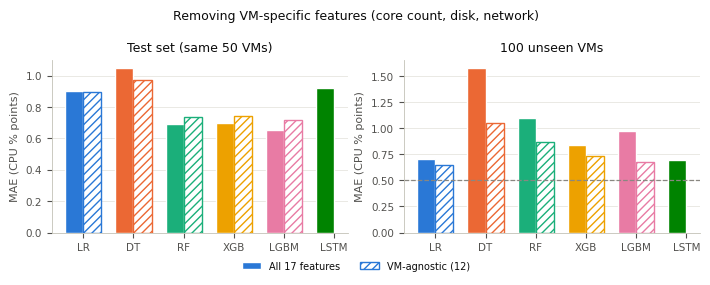

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(P.TWO_COL, 2.6), sharey=False)
names = M.TABULAR_MODELS
x = np.arange(len(names) + 1); w = 0.36
for ax, part, title in ((axes[0], 'test', 'Test set (same 50 VMs)'), (axes[1], 'unseen', '100 unseen VMs')):
    full = [R['train'][n][part]['MAE'] for n in names] + [R['train']['LSTM'][part]['MAE']]
    agn = [R['train'][f'{n} (VM-agnostic)'][part]['MAE'] for n in names] + [np.nan]
    colors = [P.COLOR[n] for n in names] + [P.COLOR['LSTM']]
    ax.bar(x - w / 2, full, width=w, color=colors, edgecolor='white', label='All 17 features')
    ax.bar(x + w / 2, agn, width=w, color='white', edgecolor=colors, hatch='////', linewidth=1, label='VM-agnostic (12)')
    ax.set_xticks(x, [P.SHORT[n] for n in names] + ['LSTM'])
    ax.grid(axis='x', visible=False)
    ax.set_title(title)
    ax.set_ylabel('MAE (CPU % points)')
    if part == 'unseen':
        ax.axhline(persist['MAE'], color=P.MUTED, ls='--', lw=0.9)
        ax.annotate('persistence', (len(x) - 0.5, persist['MAE']), xytext=(0, 2), textcoords='offset points',
                    ha='right', va='bottom', fontsize=6.5, color=P.MUTED)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=False)
fig.suptitle('Removing VM-specific features (core count, disk, network)', fontsize=9)
P.save_fig(fig, 'fig_ablation_generalization', log)

## 3. S3(b): Inference energy

A deployed forecaster predicts far more often than it is retrained: every VM, every 5 minutes. We measure the energy of predicting the whole test set (80,303 predictions), repeated until about 30 s, and report it **per 1,000 predictions**.

In [9]:
lstm_test_X = M.lstm_datasets(features_main, lstm_cfg['seq_len'])['test'][0]
for k in ORDER11:
    if k in R.get('infer', {}):
        log.info(f'{k}: inference already measured, skipping'); continue
    if k == 'LSTM':
        model = M.build_lstm(len(M.LSTM_SEQ_FEATURES), lstm_cfg['hidden_size'], M.LSTM_DEFAULTS['num_layers'], C.RANDOM_SEED)
        model.load_state_dict(torch.load(C.MODELS_DIR / 'phase11_lstm.pt'))
        predict = lambda: M.predict_lstm(model, lstm_test_X)
    else:
        name = R['train'][k]['model']; fs = R['train'][k]['features']
        model = joblib.load(C.MODELS_DIR / f'phase11_{fs}_{M.slug(name)}.joblib')
        Xte = test[FULL if fs == 'full' else AGNOSTIC]
        predict = lambda: model.predict(Xte)
    with U.Timer() as t1:
        predict()                                        # warm-up, also gives the time of one pass
    repeats = int(min(500, max(1, math.ceil(MIN_MEASURE_SEC / max(t1.seconds, 0.01)))))
    meas, _ = E.measure(predict, repeats, f'{k} inference')
    per_1k = {f'{m}_per_1k': meas[m] / (len(test) / 1000) for m in ('seconds', 'energy_kwh', 'co2_kg')}
    R.setdefault('infer', {})[k] = {**meas, **per_1k}; save()
    log.info(f'{k:<32} inference: {per_1k["seconds_per_1k"] * 1000:.3f} ms / 1k | '
             f'{per_1k["energy_kwh_per_1k"] * 1e6:.4f} mWh / 1k | x{repeats}')
    del model; gc.collect()

Linear Regression                inference: 0.061 ms / 1k | 0.0003 mWh / 1k | x500
Linear Regression (VM-agnostic)  inference: 0.043 ms / 1k | 0.0002 mWh / 1k | x500
Decision Tree                    inference: 0.101 ms / 1k | 0.0005 mWh / 1k | x500
Decision Tree (VM-agnostic)      inference: 0.057 ms / 1k | 0.0002 mWh / 1k | x500
Random Forest                    inference: 3.780 ms / 1k | 0.0181 mWh / 1k | x113
Random Forest (VM-agnostic)      inference: 4.095 ms / 1k | 0.0185 mWh / 1k | x114
XGBoost                          inference: 4.791 ms / 1k | 0.0208 mWh / 1k | x92
XGBoost (VM-agnostic)            inference: 4.951 ms / 1k | 0.0243 mWh / 1k | x93
LightGBM                         inference: 6.480 ms / 1k | 0.0288 mWh / 1k | x41
LightGBM (VM-agnostic)           inference: 6.738 ms / 1k | 0.0300 mWh / 1k | x62
LSTM                             inference: 12.421 ms / 1k | 0.0601 mWh / 1k | x38


## 4. S2: Robustness-aware TOPSIS over all 11 variants

**Standard ranking:** the Phase 7 primary weights over the 11 variants. **Robustness-aware ranking:** the same, plus "MAE on unseen VMs" as a seventh criterion, with weights rebalanced as follows:

| MAE | RMSE | MAPE | R² | **Unseen MAE** | Train time | CO₂ |
|---|---|---|---|---|---|---|
| 0.10 | 0.10 | 0.10 | 0.15 | **0.20** | 0.15 | 0.20 |

Accuracy on known VMs drops from 0.65 to 0.45 in total, and the 0.20 freed up goes to accuracy on *unseen* VMs. Cost stays at 0.35. All numbers here were measured in this session, including training time and CO₂.

A **sweep** then moves the weight on unseen MAE from 0 to 0.6, scaling the other weights down proportionally, to show where the recommendation changes.

In [10]:
dm = pd.DataFrame({k: {'MAE': R['train'][k]['test']['MAE'], 'RMSE': R['train'][k]['test']['RMSE'],
                       'MAPE': R['train'][k]['test']['MAPE'], 'R2': R['train'][k]['test']['R2'],
                       'unseen_MAE': R['train'][k]['unseen']['MAE'],
                       'train_time_sec': R['train'][k]['seconds'], 'co2_emissions_kg': R['train'][k]['co2_kg']}
                   for k in ORDER11}).T
dm.index.name = 'Model'
dm.to_csv(C.TABLES_DIR / 'phase11_decision_matrix_11.csv')
benefit = {**C.TOPSIS_CRITERIA, 'unseen_MAE': False}
ROBUST = {'MAE': 0.10, 'RMSE': 0.10, 'MAPE': 0.10, 'R2': 0.15, 'unseen_MAE': 0.20,
          'train_time_sec': 0.15, 'co2_emissions_kg': 0.20}

std = U.topsis(dm, C.TOPSIS_PRIMARY_WEIGHTS, benefit)
rob = U.topsis(dm, ROBUST, benefit)
topsis11 = pd.DataFrame({'Model': dm.index, 'Standard C': std['closeness'].values, 'Standard rank': std['rank'].values,
                         'Robust C': rob['closeness'].values, 'Robust rank': rob['rank'].values}).sort_values('Robust rank')
U.log_df(log, topsis11.round(4), 'S2: STANDARD vs ROBUSTNESS-AWARE TOPSIS (11 variants)')
U.save_table(topsis11, 'table_topsis_robust', 'Standard vs robustness-aware TOPSIS (11 model variants)', float_fmt='{:.4f}')
log.info(f'Standard winner: {std["closeness"].idxmax()} | robustness-aware winner: {rob["closeness"].idxmax()}')

# Same check restricted to the 6 original models (the Phase 7 set)
orig = ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM', 'LSTM']
s6, r6 = U.topsis(dm.loc[orig], C.TOPSIS_PRIMARY_WEIGHTS, benefit), U.topsis(dm.loc[orig], ROBUST, benefit)
log.info(f'Original 6 only -> standard ranks {s6["rank"].astype(int).to_dict()} | robust ranks {r6["rank"].astype(int).to_dict()}')
topsis11

--- S2: STANDARD vs ROBUSTNESS-AWARE TOPSIS (11 variants) ---
                              Model  Standard C  Standard rank  Robust C  Robust rank
9            LightGBM (VM-agnostic)      0.9600              3    0.9666            1
7             XGBoost (VM-agnostic)      0.9514              4    0.9529            2
6                           XGBoost      0.9685              1    0.9299            3
1   Linear Regression (VM-agnostic)      0.8854              5    0.9242            4
0                 Linear Regression      0.8843              6    0.9205            5
8                          LightGBM      0.9626              2    0.8858            6
3       Decision Tree (VM-agnostic)      0.8301              7    0.8312            7
2                     Decision Tree      0.7869              8    0.7144            8
10                             LSTM      0.3249              9    0.4014            9
5       Random Forest (VM-agnostic)      0.2620             10    0.3020      

,Model,Standard C,Standard rank,Robust C,Robust rank
9,LightGBM (VM-agnostic),0.959991,3,0.966642,1
7,XGBoost (VM-agnostic),0.951401,4,0.952947,2
6,XGBoost,0.968526,1,0.929851,3
1,Linear Regression (VM-agnostic),0.885414,5,0.924158,4
0,Linear Regression,0.884291,6,0.920497,5
8,LightGBM,0.962565,2,0.885760,6
3,Decision Tree (VM-agnostic),0.830105,7,0.831172,7
2,Decision Tree,0.786926,8,0.714435,8
10,LSTM,0.324905,9,0.401406,9
5,Random Forest (VM-agnostic),0.261957,10,0.302029,10


From unseen-MAE weight 0.00: winner = XGBoost
From unseen-MAE weight 0.10: winner = LightGBM (VM-agnostic)
From unseen-MAE weight 0.60: winner = Linear Regression (VM-agnostic)
Saved figure: fig_topsis_robust_sweep.png / .pdf


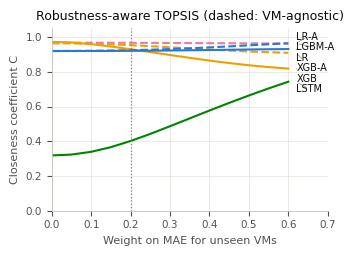

In [11]:
base = {k: v for k, v in ROBUST.items() if k != 'unseen_MAE'}
base_tot = sum(base.values())
sweep = []
for wu in np.round(np.arange(0, 0.6001, 0.05), 2):
    w = {**{k: (1 - wu) * v / base_tot for k, v in base.items()}, 'unseen_MAE': wu}
    c = U.topsis(dm, w, benefit)['closeness']
    sweep.append({'unseen_weight': wu, **{f'C_{m}': c[m] for m in dm.index}, 'winner': c.idxmax()})
sweep = pd.DataFrame(sweep)
sweep.to_csv(C.TABLES_DIR / 'phase11_robust_weight_sweep.csv', index=False)
for _, row in sweep[sweep.winner != sweep.winner.shift()].iterrows():
    log.info(f'From unseen-MAE weight {row.unseen_weight:.2f}: winner = {row.winner}')

# Chart: the 5 variants with the highest robust closeness, plus the LSTM
show = list(topsis11.Model.head(5))
if 'LSTM' not in show:
    show.append('LSTM')
names = {m: P.SHORT.get(m.replace(' (VM-agnostic)', ''), m) + ('-A' if 'agnostic' in m else '') for m in show}
fig, ax = plt.subplots(figsize=(P.ONE_COL, 2.6))
for m in show:
    base_name = m.replace(' (VM-agnostic)', '')
    ax.plot(sweep['unseen_weight'], sweep[f'C_{m}'], color=P.COLOR[base_name], lw=1.5,
            ls='--' if 'agnostic' in m else '-')
P.end_labels(ax, 0.62, {m: sweep[f'C_{m}'].iloc[-1] for m in show}, min_gap=0.06, names=names)
ax.axvline(0.20, color=P.MUTED, ls=':', lw=0.9)
ax.set_xlim(0, 0.70)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Weight on MAE for unseen VMs')
ax.set_ylabel('Closeness coefficient C')
ax.set_title('Robustness-aware TOPSIS (dashed: VM-agnostic)')
P.save_fig(fig, 'fig_topsis_robust_sweep', log)

## 5. S3(a): Is the cost side double-counted?

On Colab, training time and CO₂ are almost perfectly correlated (Phase 7: 1.000), because CodeCarbon estimates energy from run time. We re-rank the 6 original models with the two merged: all 0.35 of the cost weight on CO₂ alone, then all on time alone. If the ranks don't change, double-counting isn't distorting our results.

In [12]:
d6 = pd.read_csv(C.TABLES_DIR / 'phase7_decision_matrix.csv', index_col='Model')
acc = {k: C.TOPSIS_PRIMARY_WEIGHTS[k] for k in ('MAE', 'RMSE', 'MAPE', 'R2')}
variants = {'Primary (time 0.15 + CO2 0.20)': C.TOPSIS_PRIMARY_WEIGHTS,
            'CO2 only (0.35)': {**acc, 'co2_emissions_kg': 0.35},
            'Time only (0.35)': {**acc, 'train_time_sec': 0.35}}
merged = pd.DataFrame({'Model': d6.index})
for label, w in variants.items():
    r = U.topsis(d6, w, C.TOPSIS_CRITERIA)
    merged[f'{label} C'] = r['closeness'].values
    merged[f'{label} rank'] = r['rank'].values
same = all((merged[f'{l} rank'] == merged[f'{list(variants)[0]} rank']).all() for l in variants)
log.info(f'Correlation time vs CO2 (Phase 7 matrix): {d6.train_time_sec.corr(d6.co2_emissions_kg):.4f}')
log.info(f'Ranks identical whether cost = time+CO2, CO2 only, or time only: {same}')
U.log_df(log, merged.round(4), 'S3a: MERGED COST CRITERION')
U.save_table(merged, 'table_topsis_merged_cost', 'TOPSIS with time and CO2 merged into one cost criterion', float_fmt='{:.4f}')
merged.round(4)

Correlation time vs CO2 (Phase 7 matrix): 0.9999
Ranks identical whether cost = time+CO2, CO2 only, or time only: True
--- S3a: MERGED COST CRITERION ---
               Model  Primary (time 0.15 + CO2 0.20) C  Primary (time 0.15 + CO2 0.20) rank  CO2 only (0.35) C  CO2 only (0.35) rank  Time only (0.35) C  Time only (0.35) rank
0  Linear Regression                            0.8688                                    3             0.9022                     3              0.9016                      3
1      Decision Tree                            0.7620                                    4             0.8180                     4              0.8167                      4
2      Random Forest                            0.2201                                    6             0.1675                     6              0.1684                      6
3            XGBoost                            0.9683                                    1             0.9732                     1          

,Model,Primary (time 0.15 + CO2 0.20) C,Primary (time 0.15 + CO2 0.20) rank,CO2 only (0.35) C,CO2 only (0.35) rank,Time only (0.35) C,Time only (0.35) rank
0,Linear Regression,0.8688,3,0.9022,3,0.9016,3
1,Decision Tree,0.7620,4,0.8180,4,0.8167,4
2,Random Forest,0.2201,6,0.1675,6,0.1684,6
3,XGBoost,0.9683,1,0.9732,1,0.9677,1
4,LightGBM,0.9652,2,0.9658,2,0.9621,2
5,LSTM,0.2286,5,0.2167,5,0.2058,5


## 6. S3(c): Fleet-scale projection

**This is a projection, not a measurement.** It scales the energy we measured to a realistic deployment, using the scenario set at the top of the notebook:
- **10,000 VMs**, in groups of 50, with **one model per group** (like our experiment): 200 models.
- **Each model retrained once a day** on data like ours.
- **One forecast per VM every 5 minutes:** 288 per day, about 1.05 billion a year.

Yearly energy = (training energy × 200 models × 365) + (energy per prediction × 1.05 billion). CO₂ uses the same grid intensity measured here.

The projection assumes energy scales linearly with the number of models and predictions, and leaves out data loading, monitoring and cooling (so no PUE factor). The paper must state these assumptions next to the numbers.

In [13]:
n_models = FLEET['n_vms'] / FLEET['vms_per_model']
trainings = n_models * FLEET['retrains_per_day'] * FLEET['days']
predictions = FLEET['n_vms'] * (24 * 60 / FLEET['prediction_interval_min']) * FLEET['days']
intensity = first['carbon_intensity_kg_per_kwh']
log.info(f'Fleet: {n_models:.0f} models, {trainings:,.0f} trainings/yr, {predictions:,.0f} predictions/yr')

fleet = []
for k in ORDER11:
    tr_kwh = R['train'][k]['energy_kwh'] * trainings
    inf_kwh = R['infer'][k]['energy_kwh_per_1k'] * predictions / 1000
    fleet.append({'Model': k, 'Training (kWh/yr)': tr_kwh, 'Inference (kWh/yr)': inf_kwh,
                  'Total (kWh/yr)': tr_kwh + inf_kwh, 'Total CO2 (kg/yr)': (tr_kwh + inf_kwh) * intensity,
                  'Inference share (%)': 100 * inf_kwh / (tr_kwh + inf_kwh)})
fleet = pd.DataFrame(fleet)
best = fleet.loc[fleet['Total CO2 (kg/yr)'].idxmin()]
fleet['vs lowest (x)'] = fleet['Total CO2 (kg/yr)'] / best['Total CO2 (kg/yr)']
U.log_df(log, fleet.round(3), 'S3c: FLEET PROJECTION (10,000 VMs, daily retraining, 5-min forecasts, 1 year)')
U.save_table(fleet, 'table_fleet_projection', 'Projected yearly energy and CO2 for a 10,000-VM fleet', float_fmt='{:.4g}')
fleet.round(3)

Fleet: 200 models, 73,000 trainings/yr, 1,051,200,000 predictions/yr
--- S3c: FLEET PROJECTION (10,000 VMs, daily retraining, 5-min forecasts, 1 year) ---
                              Model  Training (kWh/yr)  Inference (kWh/yr)  Total (kWh/yr)  Total CO2 (kg/yr)  Inference share (%)  vs lowest (x)
0                 Linear Regression              0.101               0.000           0.101              0.037                0.289          2.027
1   Linear Regression (VM-agnostic)              0.050               0.000           0.050              0.018                0.456          1.000
2                     Decision Tree              0.512               0.001           0.513              0.189                0.103         10.260
3       Decision Tree (VM-agnostic)              0.435               0.000           0.435              0.161                0.048          8.703
4                     Random Forest             66.853               0.019          66.872             24.707      

,Model,Training (kWh/yr),Inference (kWh/yr),Total (kWh/yr),Total CO2 (kg/yr),Inference share (%),vs lowest (x)
0,Linear Regression,0.101,0.000,0.101,0.037,0.289,2.027
1,Linear Regression (VM-agnostic),0.050,0.000,0.050,0.018,0.456,1.000
2,Decision Tree,0.512,0.001,0.513,0.189,0.103,10.260
3,Decision Tree (VM-agnostic),0.435,0.000,0.435,0.161,0.048,8.703
4,Random Forest,66.853,0.019,66.872,24.707,0.028,1338.341
5,Random Forest (VM-agnostic),54.502,0.019,54.521,20.144,0.036,1091.165
6,XGBoost,1.472,0.022,1.494,0.552,1.467,29.893
7,XGBoost (VM-agnostic),1.233,0.026,1.259,0.465,2.030,25.196
8,LightGBM,2.642,0.030,2.672,0.987,1.132,53.474
9,LightGBM (VM-agnostic),1.700,0.031,1.732,0.640,1.819,34.659


Saved figure: fig_fleet_projection.png / .pdf


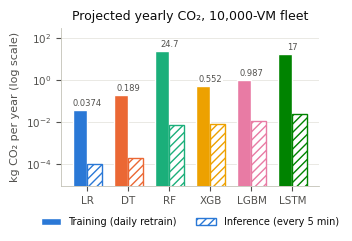

In [14]:
show = ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM', 'LSTM']
f = fleet.set_index('Model').loc[show]
fig, ax = plt.subplots(figsize=(P.ONE_COL, 2.5))
x = np.arange(len(show)); w = 0.36
colors = [P.COLOR[m] for m in show]
ax.bar(x - w / 2, f['Training (kWh/yr)'] * intensity, width=w, color=colors, edgecolor='white', label='Training (daily retrain)')
ax.bar(x + w / 2, f['Inference (kWh/yr)'] * intensity, width=w, color='white', edgecolor=colors, hatch='////',
       linewidth=1, label='Inference (every 5 min)')
for xi, v in zip(x, f['Total CO2 (kg/yr)']):
    ax.annotate(f'{v:.3g}', (xi, max(f.iloc[xi]['Training (kWh/yr)'], f.iloc[xi]['Inference (kWh/yr)']) * intensity),
                xytext=(0, 3), textcoords='offset points', ha='center', fontsize=6, color=P.INK2,
                bbox=dict(boxstyle='square,pad=0.1', fc='white', ec='none'))
ax.set_yscale('log')
ax.set_xticks(x, [P.SHORT[m] for m in show])
ax.grid(axis='x', visible=False)
ax.set_ylabel('kg CO₂ per year (log scale)')
ax.set_title('Projected yearly CO₂, 10,000-VM fleet')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
ax.margins(y=0.2)
P.save_fig(fig, 'fig_fleet_projection', log)

## 7. S4: Is XGBoost really different from LightGBM?

Two tests on the original tuned models:
1. **VM-level paired test:** compute each model's MAE separately for every VM, then compare the two lists with a Wilcoxon signed-rank test (and a paired t-test). Each VM counts as one independent case, which avoids treating 80,000 correlated 5-minute errors as independent.
2. **Diebold–Mariano test:** the standard test for comparing two forecasters, on absolute errors, with a Newey–West variance that allows for autocorrelation (lag 12 = 1 hour).

Each test runs on the test set (50 VMs) and on the unseen VMs (100 VMs). **p < 0.05** means the difference is unlikely to be chance.

In [15]:
def dm_test(e1, e2, lag=12):
    d = np.abs(e1) - np.abs(e2)
    n = len(d); dbar = d.mean(); dc = d - dbar
    gamma = [np.dot(dc[k:], dc[:n - k]) / n for k in range(lag + 1)]
    var = gamma[0] + 2 * sum((1 - k / (lag + 1)) * gamma[k] for k in range(1, lag + 1))
    stat = dbar / np.sqrt(var / n)
    return float(stat), float(2 * (1 - stats.norm.cdf(abs(stat))))

def compare(a, b):
    out = []
    for part, y, vm, loader in (('test', y_test, test['vm_id'], 'test'), ('unseen', y_gen, common['vm_id'], 'gen')):
        pa = np.load(C.MODELS_DIR / f'phase11_pred_{loader}_full_{M.slug(a)}.npy')
        pb = np.load(C.MODELS_DIR / f'phase11_pred_{loader}_full_{M.slug(b)}.npy')
        ma = pd.Series(np.abs(pa - y)).groupby(np.asarray(vm)).mean()
        mb = pd.Series(np.abs(pb - y)).groupby(np.asarray(vm)).mean()
        w = stats.wilcoxon(ma, mb)
        t = stats.ttest_rel(ma, mb)
        dm_stat, dm_p = dm_test(pa - y, pb - y)
        out.append({'Comparison': f'{a} vs {b}', 'Data': f'{part} ({vm.nunique()} VMs)',
                    f'MAE {P.SHORT[a]}': np.abs(pa - y).mean(), f'MAE {P.SHORT[b]}': np.abs(pb - y).mean(),
                    'VMs where A better': int((ma < mb).sum()), 'Wilcoxon p': w.pvalue, 'Paired t p': t.pvalue,
                    'DM stat': dm_stat, 'DM p': dm_p})
    return out

sig = pd.DataFrame(compare('XGBoost', 'LightGBM') + compare('LightGBM', 'LSTM') + compare('XGBoost', 'Linear Regression'))
U.log_df(log, sig.round(4), 'S4: SIGNIFICANCE TESTS (A vs B; DM stat < 0 means A has smaller errors)')
sig.to_csv(C.TABLES_DIR / 'table_significance_tests.csv', index=False)
U.save_table(sig.rename(columns=lambda c: c.replace('MAE ', 'MAE ')), 'table_significance_tests',
             'Significance tests between models (p < 0.05 = significant)', float_fmt='{:.3g}')
log.info('PHASE 11 EXTENSIONS COMPLETE')
sig.round(4)

--- S4: SIGNIFICANCE TESTS (A vs B; DM stat < 0 means A has smaller errors) ---
                     Comparison              Data  MAE XGB  MAE LGBM  VMs where A better  Wilcoxon p  Paired t p  DM stat  DM p  MAE LSTM  MAE LR
0           XGBoost vs LightGBM     test (50 VMs)   0.6985    0.6568                  23      0.0772      0.0053  10.1038   0.0       NaN     NaN
1           XGBoost vs LightGBM  unseen (100 VMs)   0.8367    0.9724                  29      0.0000      0.7060  -9.4917   0.0       NaN     NaN
2              LightGBM vs LSTM     test (50 VMs)      NaN    0.6568                  46      0.0000      0.0009 -16.9013   0.0    0.9238     NaN
3              LightGBM vs LSTM  unseen (100 VMs)      NaN    0.9724                  80      0.0000      0.4580  18.8680   0.0    0.6959     NaN
4  XGBoost vs Linear Regression     test (50 VMs)   0.6985       NaN                  44      0.0000      0.0061 -13.3047   0.0       NaN  0.9032
5  XGBoost vs Linear Regression  unseen (100

,Comparison,Data,MAE XGB,MAE LGBM,VMs where A better,Wilcoxon p,Paired t p,DM stat,DM p,MAE LSTM,MAE LR
0,XGBoost vs LightGBM,test (50 VMs),0.6985,0.6568,23,0.0772,0.0053,10.1038,0.0,NaN,NaN
1,XGBoost vs LightGBM,unseen (100 VMs),0.8367,0.9724,29,0.0000,0.7060,-9.4917,0.0,NaN,NaN
2,LightGBM vs LSTM,test (50 VMs),NaN,0.6568,46,0.0000,0.0009,-16.9013,0.0,0.9238,NaN
3,LightGBM vs LSTM,unseen (100 VMs),NaN,0.9724,80,0.0000,0.4580,18.8680,0.0,0.6959,NaN
4,XGBoost vs Linear Regression,test (50 VMs),0.6985,NaN,44,0.0000,0.0061,-13.3047,0.0,NaN,0.9032
5,XGBoost vs Linear Regression,unseen (100 VMs),0.8367,NaN,68,0.0813,0.1357,22.5828,0.0,NaN,0.7069


## Done: what to check

- **S1:** did *Unseen MAE* and *Worst-VM MAE* drop for the VM-agnostic tree models, and by how much did *Test MAE* rise? A small loss on known VMs for a big gain on new ones is the trade-off the paper should highlight.
- **S2:** did the winner change when robustness is included? Where does the switch happen in the sweep?
- **S3:** are the ranks unchanged with a merged cost criterion? Is inference or training the bigger share of the fleet's yearly CO₂, and how many times more CO₂ do the expensive models emit?
- **S4:** is XGBoost vs LightGBM significant (p < 0.05)? If not, the paper calls them tied.